# Mock lensed-supernova difference imaging with the Rubin AP pipeline --- Setup B

Runs the real Rubin Alert Production difference-imaging path
(`AlardLuptonSubtractTask` -> `DetectAndMeasureTask` -> `AssociationTask`) on simulated
lensed-supernova images, scores every DIASource with two real/bogus CNNs, and keeps the
postage-stamp triplets.

The DIAObject position is the unweighted spherical mean of its full DIASource history,
recomputed after every visit and used to match the next one, as in production.

**Setup B.** GLEE catalogue (`glee_catalog2.npz`): physically correlated magnifications, time delays and image geometry.

The two setup notebooks are identical except for the input cell below.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import subprocess, os

import lsst.afw.image as afwImage
import lsst.afw.math  as afwMath
import lsst.afw.geom  as afwGeom
import lsst.meas.algorithms as measAlg
from lsst.geom import SpherePoint, degrees, Point2D, Extent2I, averageSpherePoint
from lsst.ip.diffim.subtractImages   import AlardLuptonSubtractTask, _subtractImages
from lsst.ip.diffim.detectAndMeasure import DetectAndMeasureTask
from lsst.ap.association.association import AssociationTask

#from Gen_dummy_time_series import generate_one_sample

In [2]:
# ── Real/bogus CNN models ────────────────────────────────────────────────────
# Two packaged models, each a self-contained directory holding the architecture,
# the trained weights and a metadata file:
#   v0.1   rb_models/tac_cnn_comcam_2025-02-18    trained on ComCam  + injections
#   v0.3   rb_models/tac_cnn_lsstcam_2026-02-26   trained on LSSTCam + injections
# Both take a 51x51x3 (difference, science, template) cutout and return P(real).
import os, torch
from importlib.machinery import SourceFileLoader

RB_MODEL_DIR   = "rb_models"
RB_CUTOUT_SIZE = 51          # side of the cutout fed to the RB model, pixels
STAMP_SIZE     = 30          # side of the postage stamps kept for inspection, pixels


def load_rb_model(name):
    """Load a packaged real/bogus CNN from rb_models/<name>/."""
    d = os.path.join(RB_MODEL_DIR, name)
    arch = next(f for f in ("architecture", "arch.py") if os.path.exists(os.path.join(d, f)))
    ckpt = next(f for f in ("checkpoint", "checkpoint.pt") if os.path.exists(os.path.join(d, f)))
    TACCNN = SourceFileLoader("arch_" + name, os.path.join(d, arch)).load_module().TACCNN
    model = TACCNN(input_shape=(3, RB_CUTOUT_SIZE, RB_CUTOUT_SIZE))
    model.load_state_dict(torch.load(os.path.join(d, ckpt),
                                     map_location="cpu")["model_state_dict"])
    model.eval()
    return model


rb_v01 = load_rb_model("tac_cnn_comcam_2025-02-18")
rb_v03 = load_rb_model("tac_cnn_lsstcam_2026-02-26")
print("RB models loaded: v0.1 (ComCam), v0.3 (LSSTCam)")

RB models loaded: v0.1 (ComCam), v0.3 (LSSTCam)


In [3]:
def print_params():

    print("\n" + "="*60)
    print("Selected lens")
    print("="*60)
    
    print(f"Morphology    : {morphology}")
    print(f"Theta_E       : {cat['theta_E'][idx]:.2f} arcsec")
    print(f"prtb          : {cat['prtb'][idx]:.3f}")
    print(f"z_lens        : {cat['z_lens'][idx]:.2f}")
    print(f"vel_disp_kms  : {cat['vel_disp_kms'][idx]:.0f}")
    print(f"z_src         : {cat['z_src'][idx]:.3f}")
    print(f"N_images      : {cat['nim'][idx]}")
    
    print("\nImage properties")
    print("-"*60)
    
    for i in range(int(cat["nim"][idx])):
        print(
            f"img {i+1}: "
            f"x={cat['x'][idx][i]:6.3f}\"  "
            f"y={cat['y'][idx][i]:6.3f}\"  "
            f"mu={cat['mu'][idx][i]:6.2f}  "
            f"dt={cat['dt'][idx][i]:6.2f} d"
        )
    
    print("="*60 + "\n")
    #return f"{morphology_name}_rE{theta_E:.1f}_prtb{prtb:.2f}"

# ------------------------------------------------------------------
# Fixed parameters
# ------------------------------------------------------------------
seed=45

ellip = 0.3
theta_deg = -30.0

H0 = 70.0
Om0 = 0.3

npix = 101
pix_size = 0.2
R50_arcsec, n_sersic, I_e, ellip, theta_deg = 1.2, 4.0, 20.0, 0.3, -30.0
A_LC, T0_LC = 0.35, 20.0
var_bg, C_t = 2.0, 0.05

fwhm_tmpl   = 0.6
t_tmpl      = 0.0
#t_visits    = [12,  20, 35, 65,  80,   105, 140, 175,220, ]
t_visits    = [8, 12, 20, 35, 65,  80,   105, 140, 175 ]
fwhm_visits = [0.9, 1.0, 1.2, 2.1, 1.1, 1.4, 1.61, 0.8, 1.1]
#-----------------------------------------------------------------------------

cat = np.load("glee_catalog2.npz")
print("catalog keys:", cat.keys())

MORPH_INV = {0: "cross", 1: "cusp", 2: "fold", 3: "double"}

print("Available theta_E:")
print(np.unique(cat["theta_E"]))

print("\nAvailable morphologies:")
for m in np.unique(cat["morphology_code"]):
    print(f"{m}: {MORPH_INV[int(m)]}")

theta_E = 1.5
morphology_idx = 2
morphology = MORPH_INV[morphology_idx]

vel_disp_kms=500
inds = np.where(
    (cat["morphology_code"] == morphology_idx) &
    np.isclose(cat["theta_E"], theta_E) & np.isclose(cat["vel_disp_kms"], vel_disp_kms)
)[0]

print(f"{len(inds)} matching systems")

#================
idx=inds[1]
#====================

nim = int(cat["nim"][idx])

x = cat["x"][idx][:nim]
y = cat["y"][idx][:nim]

mags = cat["mu"][idx][:nim]
time_delays = cat["dt"][idx][:nim]

cx = cy = npix // 2
image_locs = [(int(round(cx + xx/pix_size)),
               int(round(cy + yy/pix_size)))
              for xx, yy in zip(x, y)]
#=============
print_params()
#===============
rng = np.random.default_rng(seed)
sersic_kw = dict(R50_arcsec=R50_arcsec, n_sersic=n_sersic, I_e=I_e,
                 ellip=ellip, theta=np.deg2rad(theta_deg),
                 npix=npix, pix_size=pix_size, var_bg=var_bg, C_t=C_t,
                 A_LC=A_LC, T0_LC=T0_LC, rng=rng)


import Fake_LSNe_gen as Fake_LSNe_gen


[template], lc_tmpl, lrg = Fake_LSNe_gen.generate_sample(
    times=t_tmpl, fwhms=fwhm_tmpl,
    image_locs=None, mags=None, time_delays=None,
    **sersic_kw)

visit_frames, lightcurves, _ = Fake_LSNe_gen.generate_sample(
    times=t_visits, fwhms=fwhm_visits,
    image_locs=image_locs, mags=mags, time_delays=time_delays,
    **sersic_kw)

kernels = Fake_LSNe_gen.matching_kernels_from_fwhms(fwhm_tmpl, fwhm_visits, npix=npix, pix_size=pix_size)
for f, k in zip(visit_frames, kernels):
    f["kernel"] = k.astype(np.float32)
template["kernel"] = np.zeros_like(template["psf"])
template["kernel"][npix//2, npix//2] = 1.0

# Names used identically by both setups downstream
sample_name  = f"{morphology}_rE{cat['theta_E'][idx]:.1f}_prtb{cat['prtb'][idx]:.2f}"
FIRST_OBJ_ID = 1

catalog keys: KeysView(NpzFile 'glee_catalog2.npz' with keys: theta_E, z_lens, vel_disp_kms, morphology_code, prtb...)
Available theta_E:
[0.1 0.3 0.5 0.6 0.7 0.9 1.1 1.5 1.8 2.  2.2 2.4 2.6 3.  3.5]

Available morphologies:
0: cross
1: cusp
2: fold
3: double
5 matching systems

Selected lens
Morphology    : fold
Theta_E       : 1.50 arcsec
prtb          : 0.200
z_lens        : 0.30
vel_disp_kms  : 500
z_src         : 0.388
N_images      : 4

Image properties
------------------------------------------------------------
img 1: x= 0.982"  y= 1.266"  mu=  4.49  dt=  0.00 d
img 2: x=-0.496"  y=-1.420"  mu=  5.75  dt= 24.40 d
img 3: x= 1.113"  y=-0.884"  mu=  4.36  dt= 43.82 d
img 4: x=-1.214"  y= 0.528"  mu=  3.07  dt= 65.48 d



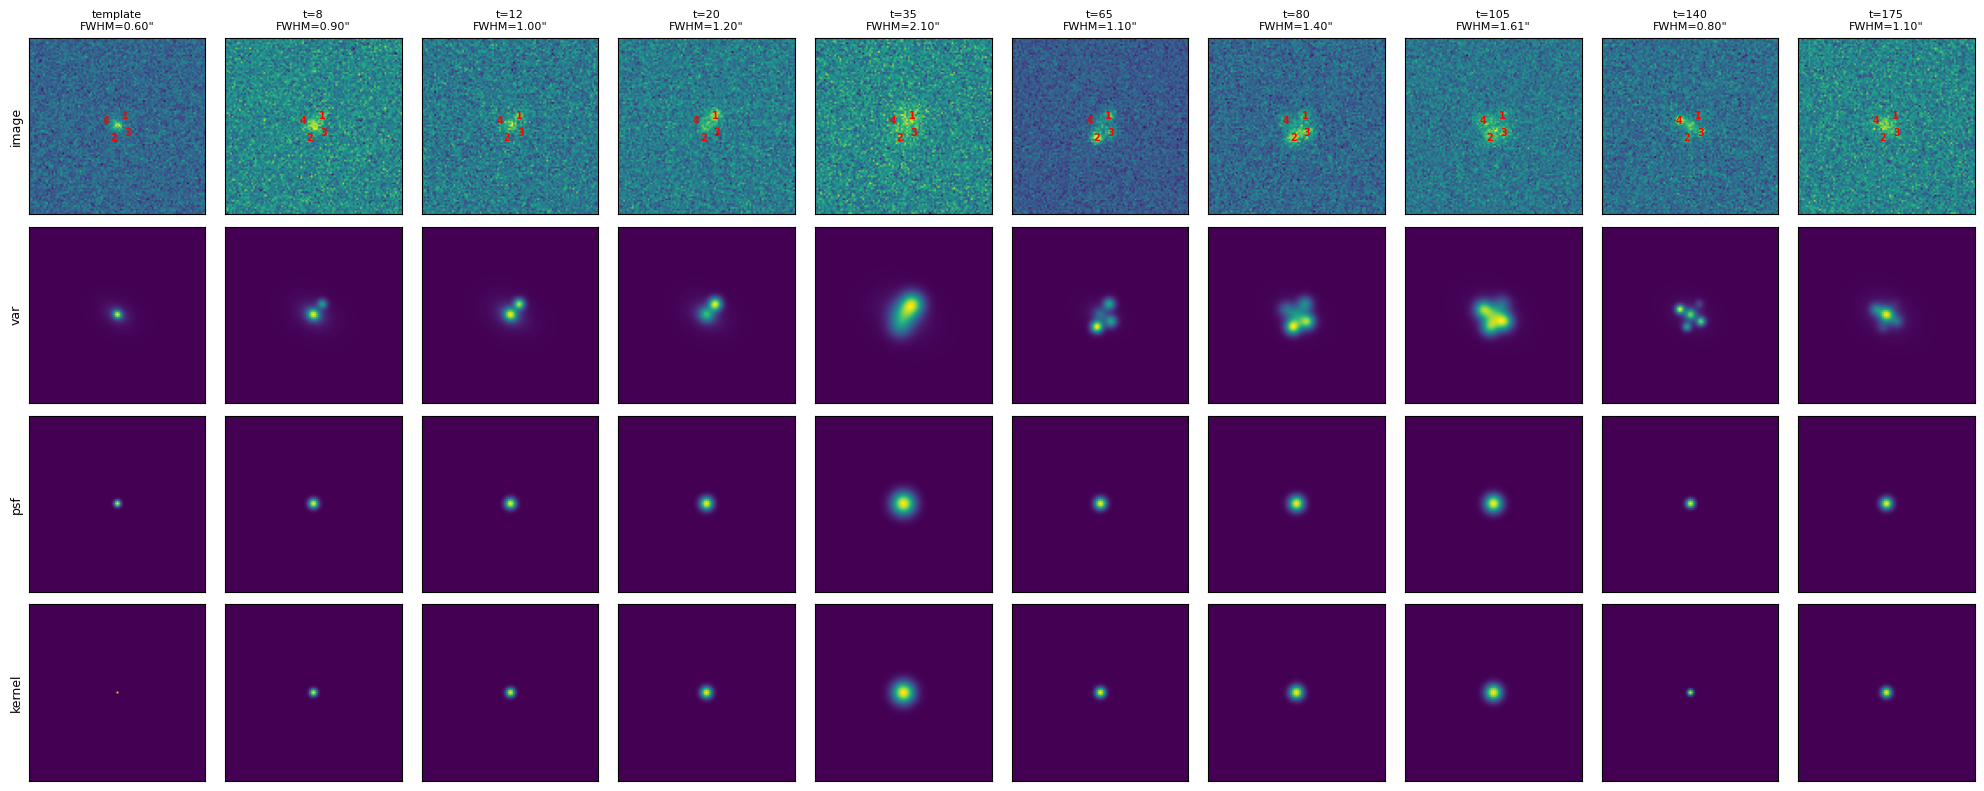

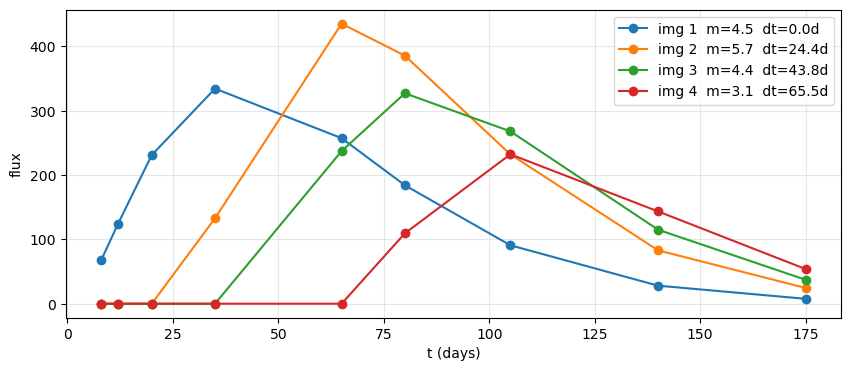

In [4]:
def plot_lightcurves(t, lc, labels, colors=None, ax=None, title=None, **plot_kw):
    """
    t      : (Nt,)
    lc     : (N, Nt)
    labels : list of N strings
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    if colors is None:
        colors = [f"C{i}" for i in range(lc.shape[0])]
    for i, (lab, col) in enumerate(zip(labels, colors)):
        ax.plot(t, lc[i], "o-", color=col, label=lab, **plot_kw)
    ax.set_xlabel("t (days)"); ax.set_ylabel("flux")
    if title: ax.set_title(title)
    ax.legend(); ax.grid(alpha=0.3)
    return ax


def plot_frames(samples, rows=("image", "var", "psf", "kernel"),
                mark_locs=None, mark_color="red"):
    ncols = len(samples)
    fig, axes = plt.subplots(len(rows), ncols, figsize=(2*ncols, 2*len(rows)))
    for j, s in enumerate(samples):
        label = "template" if j == 0 else f"t={s['t']:.0f}"
        axes[0, j].set_title(f"{label}\nFWHM={s['fwhm']:.2f}\"", fontsize=8)
        for i, key in enumerate(rows):
            ax = axes[i, j]
            ax.imshow(s[key], cmap="viridis", origin="lower")
            ax.set_xticks([]); ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(key, fontsize=9)
            if key == "image" and mark_locs is not None:
                for idx, (m, n) in enumerate(mark_locs):
                    ax.text(m, n, str(idx+1), color=mark_color,
                            fontsize=7, ha="center", va="center", fontweight="bold")
    plt.tight_layout()
    return fig
Nim     = lightcurves.shape[0]

lc_labels = [f"img {i+1}  m={mags[i]:.1f}  dt={time_delays[i]:.1f}d"
             for i in range(Nim)]

plot_frames([template]+visit_frames, mark_locs=image_locs)
plt.show()

plot_lightcurves(t_visits, lightcurves, labels=lc_labels)
plt.show()

In [5]:
visits  = visit_frames
t_true  = [v['t'] for v in visits]
F_true  = lightcurves          # shape (Nim, Nvisits) — differs from single-SN scalar F

In [6]:
def trim_to_npix_raw(arr, npix):
    c = arr.shape[0] // 2
    h = npix // 2
    trimmed = arr[c-h:c+h+1, c-h:c+h+1]
    return trimmed


def get_trim_npix(arr, min_npix=15, flux_threshold=0.999, max_npix=21):
    tot_flux=arr.sum()
    for npix in range(min_npix, max_npix + 1, 2):
        trimmed_arr=trim_to_npix_raw(arr, npix); trimmed_flux=trimmed_arr.sum()
        if trimmed_flux/tot_flux>= flux_threshold:
            return npix, trimmed_arr, trimmed_flux
    return max_npix, trimmed_arr, trimmed_flux


def trim_psf_and_kernel(arr_psf, arr_ker, min_npix=11, flux_threshold=0.999, max_npix=25):
    psf_npix,psf_trimmed,psf_trimmed_flux = get_trim_npix(arr_psf, min_npix, flux_threshold, max_npix)
    ker_npix,ker_trimmed,ker_trimmed_flux = get_trim_npix(arr_ker, min_npix, flux_threshold, max_npix)
    psf_trimmed=psf_trimmed/psf_trimmed.sum(); ker_trimmed=ker_trimmed/ker_trimmed.sum(); 
    return psf_trimmed, ker_trimmed, psf_npix, ker_npix, psf_trimmed_flux, ker_trimmed_flux


flux_threshold = 0.999

tmpl_psf, tmpl_ker, tn_psf, tn_ker, tf_psf, tf_ker = trim_psf_and_kernel(template['psf'], template['kernel'], flux_threshold=flux_threshold)
print(f"Template: psf={tmpl_psf.shape} flux={tf_psf:.6f}  ker={tmpl_ker.shape} flux={tf_ker:.6f}")

visit_psfs, visit_kers = [], []
for i, v in enumerate(visits):
    psf, ker, vn_psf, vn_ker, vf_psf, vf_ker = trim_psf_and_kernel(v['psf'], v['kernel'],flux_threshold=flux_threshold)
    visit_psfs.append(psf)
    visit_kers.append(ker)
    print(f"Visit {i:02d}: psf={psf.shape} flux={vf_psf:.6f}  ker={ker.shape} flux={vf_ker:.6f}")

Template: psf=(11, 11) flux=0.999981  ker=(11, 11) flux=1.000000
Visit 00: psf=(15, 15) flux=0.999856  ker=(11, 11) flux=0.999836
Visit 01: psf=(15, 15) flux=0.999272  ker=(13, 13) flux=0.999792
Visit 02: psf=(19, 19) flux=0.999650  ker=(17, 17) flux=0.999795
Visit 03: psf=(25, 25) flux=0.990093  ker=(25, 25) flux=0.993275
Visit 04: psf=(17, 17) flux=0.999509  ker=(15, 15) flux=0.999785
Visit 05: psf=(21, 21) flux=0.999226  ker=(19, 19) flux=0.999251
Visit 06: psf=(25, 25) flux=0.999514  ker=(23, 23) flux=0.999455
Visit 07: psf=(13, 13) flux=0.999792  ker=(11, 11) flux=0.999999
Visit 08: psf=(17, 17) flux=0.999509  ker=(15, 15) flux=0.999785


In [7]:
# ── Helper: numpy array → lsst ExposureF ─────────────────────────────────────
def make_exposure(image_arr, var_arr, psf_arr, band='r',
                  ra_deg=0.0, dec_deg=0.0, pixel_scale_arcsec=0.2):
    ny, nx = image_arr.shape
    exp = afwImage.ExposureF(nx, ny)
    exp.image.array[:]    = image_arr.astype(np.float32)
    exp.variance.array[:] = var_arr.astype(np.float32)
    exp.setFilter(afwImage.FilterLabel(band=band))
    exp.setPhotoCalib(afwImage.PhotoCalib(1.0))
    # PSF
    psf_img = afwImage.ImageD(psf_arr.shape[1], psf_arr.shape[0])
    psf_img.array[:] = (psf_arr / psf_arr.sum()).astype(np.float64)
    exp.setPsf(measAlg.KernelPsf(afwMath.FixedKernel(psf_img)))
    # WCS
    crpix = Point2D(nx / 2, ny / 2)
    crval = SpherePoint(ra_deg * degrees, dec_deg * degrees)
    exp.setWcs(afwGeom.makeSkyWcs(
        crpix=crpix, crval=crval,
        cdMatrix=afwGeom.makeCdMatrix(scale=(pixel_scale_arcsec / 3600) * degrees)))
    return exp


def make_lck(kernel_arr):
    """Wrap a numpy kernel as LinearCombinationKernel."""
    k = kernel_arr.astype(np.float64)
    k /= k.sum()
    img = afwImage.ImageD(k.shape[1], k.shape[0])
    img.array[:] = k
    return afwMath.LinearCombinationKernel([afwMath.FixedKernel(img)], [1.0])

def make_lck_cropped(kernel_arr, target_npix=21):
    """Crop kernel to target_npix x target_npix before wrapping as LCK."""
    c = kernel_arr.shape[0] // 2
    h = target_npix // 2
    k = kernel_arr[c-h:c+h+1, c-h:c+h+1].astype(np.float64)
    k /= k.sum()
    img = afwImage.ImageD(k.shape[1], k.shape[0])
    img.array[:] = k
    return afwMath.LinearCombinationKernel([afwMath.FixedKernel(img)], [1.0])

In [8]:
# ── Initialise pipeline tasks ─────────────────────────────────────────────────
sub_config = AlardLuptonSubtractTask.ConfigClass()
#sub_config.decorrelate.completeVarianceCorrection = True
sub_task   = AlardLuptonSubtractTask(config=sub_config)
sub_task.convolutionControl.setDoCopyEdge(False)  # NaN border instead of copied pixels

det_config = DetectAndMeasureTask.ConfigClass()
det_config.detection.thresholdValue        = 5.0
det_config.detection.thresholdType         = 'pixel_stdev'
det_config.detection.thresholdPolarity     = 'both'
det_config.detection.doTempLocalBackground = False
det_config.detection.reEstimateBackground  = False
det_config.doSkySources                    = False
det_config.doMaskStreaks                   = False
det_config.raiseOnNoDiaSources             = False
det_config.doSubtractBackground            = False
# Keep sources whose footprint touches EDGE-masked pixels: on a stamp this small,
# relative to the convolution kernel, the edge mask would otherwise reject good sources.
det_config.badSourceFlags = [
    f for f in det_config.badSourceFlags
    if 'edge' not in f.lower()
]
det_task = DetectAndMeasureTask(config=det_config)

assoc_config = AssociationTask.ConfigClass()
assoc_task   = AssociationTask(config=assoc_config)

print(f"Association match radius: {assoc_config.maxDistArcSeconds} arcsec")

Association match radius: 1.0 arcsec


In [9]:
# ── Per-visit pipeline: subtract, detect, associate, score, cut out ──────────

import lsst.afw.math  as afwMath
import lsst.afw.image as afwImage



def compute_snr_map(diff_exp, psf_array):
    psf = np.ascontiguousarray(psf_array.astype(np.float64) / psf_array.sum())
    kernel = afwMath.FixedKernel(afwImage.ImageD(psf))
    mi  = diff_exp.maskedImage.Factory(diff_exp.maskedImage, deep=True)
    out = afwImage.MaskedImageF(mi.getBBox())
    afwMath.convolve(out, mi, kernel, afwMath.ConvolutionControl())
    return out.image.array / np.sqrt(out.variance.array)


def summarise_detections(det, diff_exp, snr_map):
    rows = []
    if not hasattr(det, 'diaSources'):
        return rows
    x0, y0 = diff_exp.getBBox().getBegin()
    for j, src in enumerate(det.diaSources):
        fp = src.getFootprint()
        for peak in fp.getPeaks():
            px, py = int(peak.getIx()), int(peak.getIy())
            rows.append((
                j, px, py, fp.getArea(),
                tuple(fp.getBBox().getDimensions()),
                snr_map[py - y0, px - x0],
                peak['significance'] if 'significance' in peak.getSchema().getNames() else np.nan,
            ))
    return rows


def clear_edge_mask(exp):
    bit = exp.mask.getPlaneBitMask('EDGE')
    exp.mask.array &= ~bit


def score_rb(df, sci_exp, matched_tmpl, diff_exp, model, rb_cutout_size=51):
    """Score all sources in df with a given RB model. Returns dict {diaObjectId: rb_score}."""
    inputs, meta = [], []
    extent_rb = Extent2I(rb_cutout_size, rb_cutout_size)
    for _, src in df.iterrows():
        p = Point2D(src['base_SdssCentroid_x'], src['base_SdssCentroid_y'])
        try:
            diff_cut = diff_exp.getCutout(p, extent_rb).image.array.copy()
            sci_cut  = sci_exp.getCutout(p, extent_rb).image.array.copy()
            tmpl_cut = matched_tmpl.getCutout(p, extent_rb).image.array.copy()
        except Exception:
            diff_cut = np.zeros((rb_cutout_size, rb_cutout_size), dtype=np.float32)
            sci_cut  = np.zeros_like(diff_cut)
            tmpl_cut = np.zeros_like(diff_cut)
        # Channel order: difference, science, template (from rbTransiNetInterface.py)
        inputs.append(np.stack([diff_cut, sci_cut, tmpl_cut], axis=0).astype(np.float32))
        meta.append(src['diaObjectId'])

    if not inputs:
        return {}
    blob = torch.tensor(np.stack(inputs)).float()
    with torch.no_grad():
        out = model(blob)
        scores = torch.atleast_1d(out.squeeze(-1)).numpy()
    return {oid: float(s) for oid, s in zip(meta, scores)}


# ── Build template exposure ───────────────────────────────────────────────────
tmpl_exp = make_exposure(template['image'], template['var'], tmpl_psf)

# ── Main loop ────────────────────────────────────────────────────────────────
diaObjects = pd.DataFrame(columns=['ra', 'dec'])
diaObjects.index.name = 'diaObjectId'
obj_radec_history    = {}   # diaObjectId -> [(ra, dec), ...] of all its DiaSources
handshake_violations = 0    # a DiaObject may take at most one DiaSource per visit
all_diaSources, all_stamps = [], []
next_obj_id = FIRST_OBJ_ID

for i, v in enumerate(visits):
    print("="*10, f"Visit {i:02d} t={v['t']:.1f}, FWHM={v['fwhm']:.2f}", "="*10)
    sci_exp = make_exposure(v['image'], v['var'], visit_psfs[i])
    lck     = make_lck(visit_kers[i])
    sub_task._prepareInputs(tmpl_exp, sci_exp)
    sub_result = sub_task.runConvolveTemplate(
        template=tmpl_exp, science=sci_exp,
        psfMatchingKernel=lck, backgroundModel=None,
    )
    matched_tmpl = sub_result.matchedTemplate
    diff_exp     = sub_result.difference
    matched_tmpl.setWcs(sci_exp.getWcs())
    diff_exp.setWcs(sci_exp.getWcs())

    for exp in (sci_exp, matched_tmpl, diff_exp):
        clear_edge_mask(exp)

    det   = det_task.run(science=sci_exp, matchedTemplate=matched_tmpl, difference=diff_exp)
    n_det = len(det.diaSources) if hasattr(det, 'diaSources') else 0
    snr_map = compute_snr_map(diff_exp, visit_psfs[i])
    rows    = summarise_detections(det, diff_exp, snr_map)
    sig_lookup = {}
    for j, px, py, area, bbox, my_snr, sig in rows:
        sig_lookup[j] = max(sig_lookup.get(j, -np.inf), sig)

    min_loc = np.unravel_index(np.nanargmin(snr_map), snr_map.shape)
    max_loc = np.unravel_index(np.nanargmax(snr_map), snr_map.shape)
    src_loc = (npix//2, npix//2)
    print(f"snr_map[min,max]=[{np.nanmin(snr_map):+6.2f}@({int(min_loc[0])},{int(min_loc[1])})(d={np.sqrt((min_loc[0]-src_loc[0])**2+(min_loc[1]-src_loc[1])**2):.0f}px),"
          f"{np.nanmax(snr_map):+6.2f}@({int(max_loc[0])},{int(max_loc[1])})(d={np.sqrt((max_loc[0]-src_loc[0])**2+(max_loc[1]-src_loc[1])**2):.0f}px)]"
          f"  src={snr_map[src_loc]:+.2f}  n_det={n_det}")
    for j, px, py, area, bbox, my_snr, sig in rows:
        print(f"   src {j}: peak=({px:2d},{py:2d})  fp area={area:3d} bbox={bbox}  "
              f"my_snr={my_snr:+7.2f}  pipeline sig={sig:6.2f} \n")

    if n_det == 0:
        continue

    df = det.diaSources.asAstropy().to_pandas()
    df['pipeline_sig'] = [sig_lookup.get(i, np.nan) for i in range(len(df))]
    df['visit'], df['mjd'], df['fwhm'] = i, v['t'], v['fwhm']
    df['ra']  = np.degrees(df['coord_ra'])
    df['dec'] = np.degrees(df['coord_dec'])
    df['diaObjectId'] = 0

    assoc      = assoc_task.run(df, diaObjects)
    df_matched = assoc.matchedDiaSources
    df_unassoc = assoc.unAssocDiaSources

    if len(df_unassoc) > 0:
        new_ids = range(next_obj_id, next_obj_id + len(df_unassoc))
        df_unassoc = df_unassoc.copy()
        df_unassoc['diaObjectId'] = list(new_ids)
        new = df_unassoc[['ra', 'dec', 'diaObjectId']].copy()
        next_obj_id += len(df_unassoc)
        diaObjects = pd.concat([diaObjects, new.set_index('diaObjectId')])

    df = pd.concat([df_matched, df_unassoc]).reset_index(drop=True)

    # A DiaObject takes at most one DiaSource per visit; losers start new DiaObjects.
    handshake_violations += int(df['diaObjectId'].duplicated().sum())

    # DiaObject position: unweighted spherical mean over the object's full DiaSource
    # history, recomputed after association and used to match the next visit.
    for oid, g in df.groupby('diaObjectId'):
        obj_radec_history.setdefault(oid, []).extend(zip(g['ra'], g['dec']))
        ac = averageSpherePoint([SpherePoint(r * degrees, d * degrees)
                                 for r, d in obj_radec_history[oid]])
        diaObjects.loc[oid, ['ra', 'dec']] = (ac.getRa().asDegrees(),
                                              ac.getDec().asDegrees())

    # Report where every DiaObject now sits
    for _, s in df.sort_values('diaObjectId').iterrows():
        oid = int(s['diaObjectId'])
        sep = SpherePoint(s['ra'] * degrees, s['dec'] * degrees).separation(
            SpherePoint(diaObjects.loc[oid, 'ra'] * degrees,
                        diaObjects.loc[oid, 'dec'] * degrees)).asArcseconds()
        print(f"   DiaSource (ra={s['ra']:.6f}, dec={s['dec']:.6f}) -> DiaObject {oid}"
              f"   {'[new]' if len(obj_radec_history[oid]) == 1 else '[matched]'}"
              f"   offset from updated DiaObject position = {sep:.3f}\"")
    print(f"   DiaObject positions after visit {i:02d}:")
    for oid, o in diaObjects.iterrows():
        print(f"      {int(oid):>4}  ra={o['ra']:.6f}  dec={o['dec']:.6f}"
              f"  nDiaSource={len(obj_radec_history[int(oid)])}")

    # ── RB scoring — both models ──────────────────────────────────────────────
    rb_lookup_v03 = score_rb(df, sci_exp, matched_tmpl, diff_exp, rb_v03, RB_CUTOUT_SIZE)
    rb_lookup_v01 = score_rb(df, sci_exp, matched_tmpl, diff_exp, rb_v01, RB_CUTOUT_SIZE)
    df['rb_score_v03'] = df['diaObjectId'].map(rb_lookup_v03)
    df['rb_score_v01'] = df['diaObjectId'].map(rb_lookup_v01)

    all_diaSources.append(df)

    extent = Extent2I(STAMP_SIZE, STAMP_SIZE)
    for _, src in df.iterrows():
        p = Point2D(src['base_SdssCentroid_x'], src['base_SdssCentroid_y'])
        all_stamps.append({
            'diaObjectId':    src['diaObjectId'],
            'visit':          i, 'mjd': v['t'], 'fwhm': v['fwhm'],
            'ra':             src['ra'], 'dec': src['dec'],
            'x':              src['base_SdssCentroid_x'],
            'y':              src['base_SdssCentroid_y'],
            'psf_flux':       src['base_PsfFlux_instFlux'],
            'psf_fluxErr':    src['base_PsfFlux_instFluxErr'],
            'forced_flux':    src['ip_diffim_forced_PsfFlux_instFlux'],
            'forced_fluxErr': src['ip_diffim_forced_PsfFlux_instFluxErr'],
            'snr':            src['base_PsfFlux_instFlux'] / src['base_PsfFlux_instFluxErr'],
            'is_negative':    src['is_negative'],
            'rb_score_v03':    rb_lookup_v03.get(src['diaObjectId'], np.nan),
            'rb_score_v01':    rb_lookup_v01.get(src['diaObjectId'], np.nan),
            'pipeline_sig':   src['pipeline_sig'],
            'stamp_sci':      sci_exp.getCutout(p, extent).image.array.copy(),
            'stamp_diff':     diff_exp.getCutout(p, extent).image.array.copy(),
            'stamp_tmpl':     matched_tmpl.getCutout(p, extent).image.array.copy(),
        })

print(f"\nTotal DIAObjects: {len(diaObjects)}")
print(f"Total detections: {sum(len(d) for d in all_diaSources)}")
print(f"DiaObjects: {len(diaObjects)}   handshake violations: {handshake_violations} (must be 0)")

# ── Consolidated summary ──────────────────────────────────────────────────────
cols = ['visit', 'mjd', 'fwhm', 'ra', 'dec',
        'base_SdssCentroid_x', 'base_SdssCentroid_y',
        'base_PsfFlux_instFlux', 'base_PsfFlux_instFluxErr',
        'ip_diffim_forced_PsfFlux_instFlux', 'ip_diffim_forced_PsfFlux_instFluxErr',
        'is_negative', 'diaObjectId', 'rb_score_v03', 'rb_score_v01']

if len(all_diaSources) > 0:
    summary = pd.concat(all_diaSources)[cols].reset_index(drop=True)
    summary.columns = ['visit', 'mjd', 'fwhm', 'ra', 'dec', 'x', 'y',
                       'psf_flux', 'psf_fluxErr',
                       'forced_flux', 'forced_fluxErr',
                       'is_negative', 'diaObjectId', 'rb_score_v03', 'rb_score_v01']
    summary['snr'] = summary['psf_flux'] / summary['psf_fluxErr']
    from collections import defaultdict
    stamps_by_obj = defaultdict(list)
    for s in all_stamps:
        stamps_by_obj[s['diaObjectId']].append(s)

    print(f"\nTotal DIAObjects: {len(diaObjects)}")
    print(f"Total detections: {len(summary)}")
    print(diaObjects)
    print(summary.to_string(float_format=lambda x: f"{x:.2f}"))
else:
    print("No Dia sources have been found..")

========== Visit 00 t=8.0, FWHM=0.90 ==========


Difference image does not have valid aperture correction; skipping.
Difference image does not have valid aperture correction; skipping.


snr_map[min,max]=[ -2.77@(12,39)(d=40px), +4.68@(56,55)(d=8px)]  src=-1.40  n_det=0
========== Visit 01 t=12.0, FWHM=1.00 ==========
snr_map[min,max]=[ -3.55@(36,26)(d=28px), +7.86@(56,55)(d=8px)]  src=-0.98  n_det=1
   src 0: peak=(55,56)  fp area=177 bbox=(15, 15)  my_snr=  +7.86  pipeline sig=  7.86 

   DiaSource (ra=359.999757, dec=0.000289) -> DiaObject 1   [new]   offset from updated DiaObject position = 0.000"
   DiaObject positions after visit 01:
         1  ra=359.999757  dec=0.000289  nDiaSource=1


/tmp/ipykernel_14640/4275551783.py:133: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  diaObjects = pd.concat([diaObjects, new.set_index('diaObjectId')])
/tmp/ipykernel_14640/4275551783.py:135: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df_matched, df_unassoc]).reset_index(drop=True)
Difference image does not have valid aperture correction; skipping.


========== Visit 02 t=20.0, FWHM=1.20 ==========
snr_map[min,max]=[ -3.08@(29,49)(d=21px),+13.83@(56,55)(d=8px)]  src=-0.47  n_det=1
   src 0: peak=(55,56)  fp area=355 bbox=(21, 22)  my_snr= +13.83  pipeline sig= 13.83 

   DiaSource (ra=359.999756, dec=0.000303) -> DiaObject 1   [matched]   offset from updated DiaObject position = 0.025"
   DiaObject positions after visit 02:
         1  ra=359.999757  dec=0.000296  nDiaSource=2
========== Visit 03 t=35.0, FWHM=2.10 ==========


Difference image does not have valid aperture correction; skipping.


... (7 outputs left out)

Difference image does not have valid aperture correction; skipping.


   DiaSource (ra=359.999982, dec=-0.000300) -> DiaObject 2   [matched]   offset from updated DiaObject position = 0.300"
   DiaObject positions after visit 06:
         1  ra=359.999758  dec=0.000298  nDiaSource=3
         2  ra=0.000042  dec=-0.000358  nDiaSource=3
========== Visit 07 t=140.0, FWHM=0.80 ==========
snr_map[min,max]=[ -3.39@(32,59)(d=20px),+13.47@(53,44)(d=7px)]  src=-1.10  n_det=1
   src 0: peak=(44,53)  fp area=358 bbox=(26, 23)  my_snr= +13.47  pipeline sig= 13.47 

   src 0: peak=(56,46)  fp area=358 bbox=(26, 23)  my_snr=  +8.79  pipeline sig=  8.79 

   src 0: peak=(48,43)  fp area=358 bbox=(26, 23)  my_snr=  +6.51  pipeline sig=  6.51 



Difference image does not have valid aperture correction; skipping.


   DiaSource (ra=0.000366, dec=0.000139) -> DiaObject 3   [new]   offset from updated DiaObject position = 0.000"
   DiaObject positions after visit 07:
         1  ra=359.999758  dec=0.000298  nDiaSource=3
         2  ra=0.000042  dec=-0.000358  nDiaSource=3
         3  ra=0.000366  dec=0.000139  nDiaSource=1
========== Visit 08 t=175.0, FWHM=1.10 ==========
snr_map[min,max]=[ -2.98@(25,22)(d=38px), +4.09@(51,43)(d=7px)]  src=-0.20  n_det=0

Total DIAObjects: 3
Total detections: 7
DiaObjects: 3   handshake violations: 0 (must be 0)

Total DIAObjects: 3
Total detections: 7
                     ra       dec
diaObjectId                      
1            359.999758  0.000298
2              0.000042 -0.000358
3              0.000366  0.000139
  visit    mjd  fwhm     ra   dec     x     y  psf_flux  psf_fluxErr  forced_flux  forced_fluxErr is_negative diaObjectId  rb_score_v03  rb_score_v01   snr
0     1  12.00  1.00 360.00  0.00 54.87 55.70    126.14        15.92       151.88           11

5.777777777777779
5.566666666666666
3.666666666666667


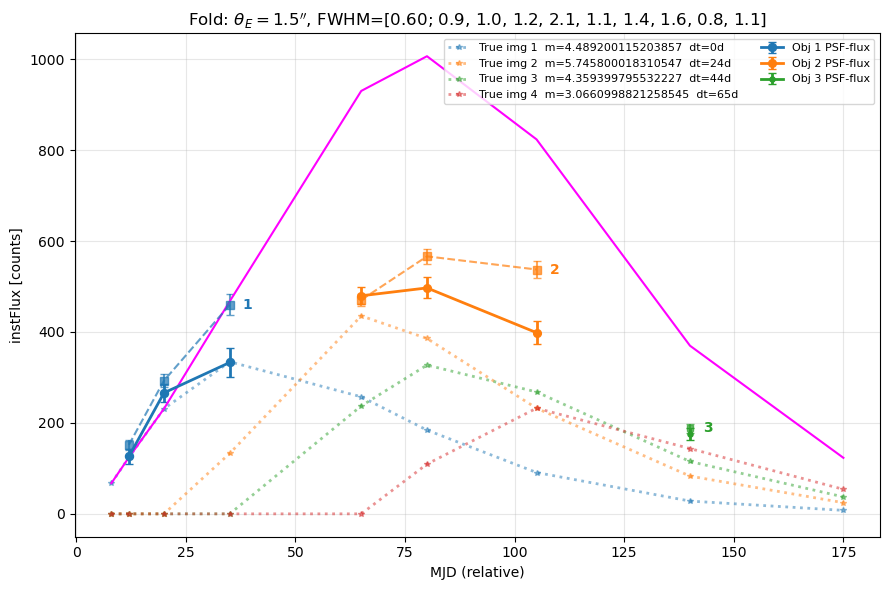

In [10]:


out_dir='./plots/'

fig, ax = plt.subplots(figsize=(9, 6))
fmin, fmax = summary['fwhm'].min(), summary['fwhm'].max()
obj_ids = sorted(summary['diaObjectId'].unique())

for i, obj_id in enumerate(obj_ids):
    df = summary[summary['diaObjectId'] == obj_id].sort_values('mjd')
    c = f'C{i}'

    ms = (3 + 8 * (df['fwhm'] - 0.6) / (2.4)).mean(); print(ms)
    ax.errorbar(df['mjd'], df['psf_flux'], yerr=df['psf_fluxErr'],
                fmt='o-', color=c, lw=2, ms=ms,
                capsize=3, label=f'Obj {obj_id} PSF-flux')

    ax.errorbar(df['mjd'], df['forced_flux'], yerr=df['forced_fluxErr'],
                fmt='s--', color=c, lw=1.5, ms=ms,
                alpha=0.7, capsize=3)#, label=f'Obj {obj_id} forced')

    ax.text(df['mjd'].iloc[-1] + 3, df['forced_flux'].iloc[-1],
            str(obj_id), color=c, fontsize=10, fontweight='bold',
            va='center')

for i in range(lightcurves.shape[0]):
    ax.plot(t_visits, lightcurves[i], ':',marker="*",ms=4.0, color=f'C{i}', alpha=0.5,
            lw=2, label=f'True img {i+1}  m={mags[i]}  dt={time_delays[i]:.0f}d')

ax.plot(t_visits,np.sum(lightcurves,axis=0), c="magenta")
ax.set_xlabel('MJD (relative)')
ax.set_ylabel('instFlux [counts]')
#ax.set_title(f'All DIAObjects ({len(obj_ids)} total)')
fwhm_str = ', '.join(f'{v["fwhm"]:.1f}' for v in visits)
ax.set_title(
    f'{morphology.capitalize()}: '
    rf'$\theta_E={theta_E:.1f}^{{\prime\prime}}$, '
    f'FWHM=[{fwhm_tmpl:.2f}; {fwhm_str}]'
)
ax.grid(alpha=0.3)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
#plt.savefig(out_dir+sample_name+'-lc.pdf', bbox_inches='tight')
plt.show()

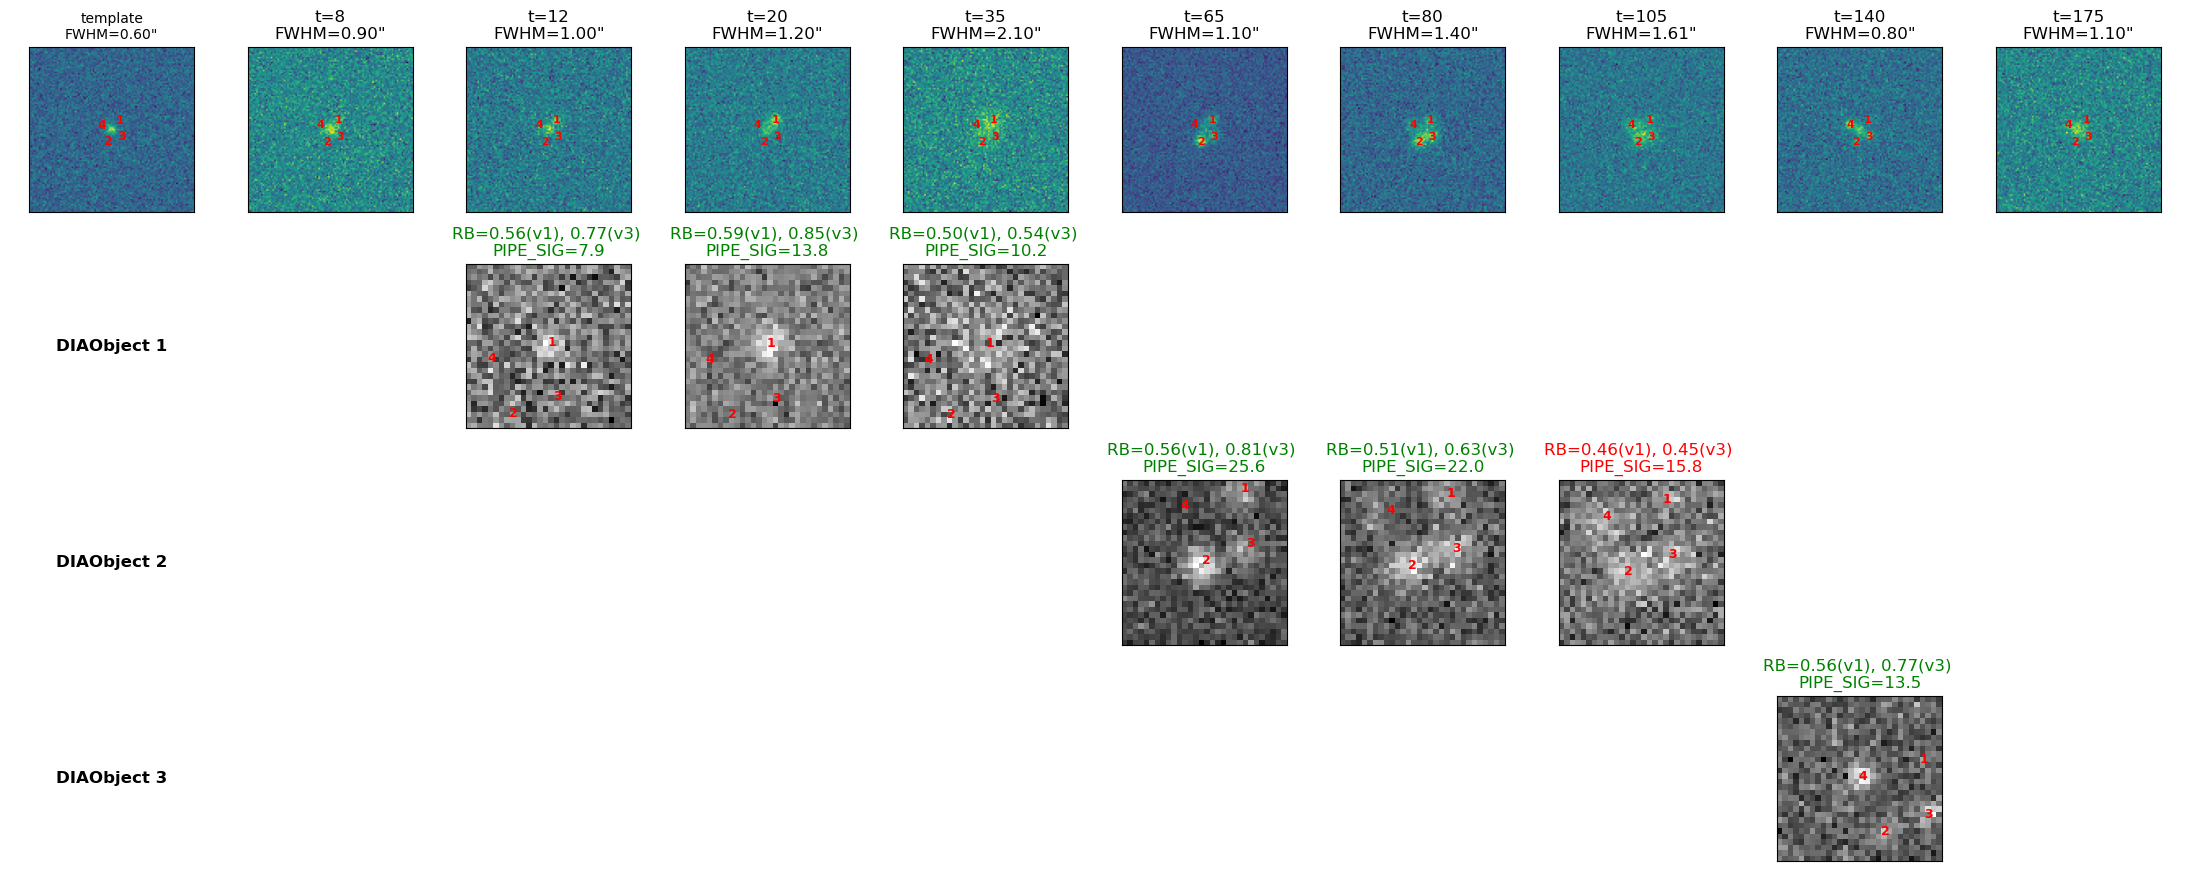

In [12]:
obj_ids = sorted(stamps_by_obj.keys())
ncols = len(visits) + 1
nrows = len(obj_ids) + 1
half = STAMP_SIZE // 2

fig, axes = plt.subplots(nrows, ncols, figsize=(2.2*ncols, 2.2*nrows))

if nrows == 1:
    axes = axes[np.newaxis, :]
if ncols == 1:
    axes = axes[:, np.newaxis]

ax = axes[0, 0]
ax.imshow(template['image'], origin='lower', cmap='viridis')
ax.set_title(f'template\nFWHM={template["fwhm"]:.2f}"', fontsize=10)
ax.set_xticks([])
ax.set_yticks([])

for idx, (x, y) in enumerate(image_locs):
    if 0 <= x < template['image'].shape[1] and 0 <= y < template['image'].shape[0]:
        ax.text(x, y, str(idx + 1), color='red', fontsize=9,
                ha='center', va='center', fontweight='bold')

for j, v in enumerate(visits, start=1):
    ax = axes[0, j]
    ax.imshow(v['image'], origin='lower', cmap='viridis')
    ax.set_title(f't={v["t"]:.0f}\nFWHM={v["fwhm"]:.2f}"', fontsize=12)
    ax.set_xticks([])
    ax.set_yticks([])

    for idx, (x, y) in enumerate(image_locs):
        if 0 <= x < v['image'].shape[1] and 0 <= y < v['image'].shape[0]:
            ax.text(x, y, str(idx + 1), color='red', fontsize=8,
                    ha='center', va='center', fontweight='bold')

for row, obj_id in enumerate(obj_ids, start=1):

    axes[row, 0].axis('off')
    axes[row, 0].text(0.5, 0.5, f'DIAObject {obj_id}',
                      transform=axes[row, 0].transAxes,
                      ha='center', va='center',
                      fontsize=12, fontweight='bold')

    stamp_dict = {s['visit']: s for s in stamps_by_obj[obj_id]}

    for j, v in enumerate(visits, start=1):

        ax = axes[row, j]
        ax.set_xticks([])
        ax.set_yticks([])

        if (j - 1) not in stamp_dict:
            ax.axis('off')
            continue

        s = stamp_dict[j - 1]
        ax.imshow(s['stamp_diff'], origin='lower', cmap='gray')
        rb1 = s.get('rb_score_v01', np.nan); rb2 = s.get('rb_score_v03', np.nan); sig = s.get('pipeline_sig', np.nan)
        #color = 'green' if rb1 >= 0.5 else 'red'
        ax.set_title(f'RB={rb1:.2f}(v1), {rb2:.2f}(v3) \nPIPE_SIG={sig:.1f}', fontsize=12,color='green' if rb2 >= 0.5 else 'red')

        cx, cy = s['x'], s['y']

        for idx, (m, n) in enumerate(image_locs):

            px = half + (m - cx)
            py = half + (n - cy)

            if 0 <= px < STAMP_SIZE and 0 <= py < STAMP_SIZE:
                ax.text(px, py, str(idx + 1), color='red',
                        fontsize=9, ha='center', va='center',
                        fontweight='bold')

plt.tight_layout()
#plt.savefig(out_dir+sample_name+'-DI_postages.pdf', bbox_inches='tight')
plt.show()